In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/dataset_heart.csv')

df.head()

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,2
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,1
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,2
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,1
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,1


In [4]:
# Check missing values in each column
print(df.isnull().sum())


age                                     0
sex                                     0
chest pain type                         0
resting blood pressure                  0
serum cholestoral                       0
fasting blood sugar                     0
resting electrocardiographic results    0
max heart rate                          0
exercise induced angina                 0
oldpeak                                 0
ST segment                              0
major vessels                           0
thal                                    0
heart disease                           0
dtype: int64


In [5]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [6]:
# Check data types
print(df.dtypes)

# Check statistical summary
print(df.describe())


age                                       int64
sex                                       int64
chest pain type                           int64
resting blood pressure                    int64
serum cholestoral                         int64
fasting blood sugar                       int64
resting electrocardiographic results      int64
max heart rate                            int64
exercise induced angina                   int64
oldpeak                                 float64
ST segment                                int64
major vessels                             int64
thal                                      int64
heart disease                             int64
dtype: object
              age        sex   chest pain type  resting blood pressure  \
count  270.000000  270.000000       270.000000              270.000000   
mean    54.433333    0.677778         3.174074              131.344444   
std      9.109067    0.468195         0.950090               17.861608   
min     29.000000 

In [7]:
# Check potential outliers using the IQR method

for col in ['resting blood pressure', 'serum cholestoral']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Potential outliers:", len(outliers))
    print(outliers[col].tolist())



resting blood pressure
Lower bound: 90.0
Upper bound: 170.0
Potential outliers: 9
[174, 178, 180, 200, 192, 178, 180, 180, 172]

serum cholestoral
Lower bound: 112.5
Upper bound: 380.5
Potential outliers: 5
[564, 407, 417, 409, 394]


In [8]:
# Display rows with potential outliers

df[
    (df['resting blood pressure'] > 170) |
    (df['serum cholestoral'] > 380.5)
]

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,1
9,63,0,4,150,407,0,2,154,0,4.0,2,3,7,2
52,65,0,3,140,417,1,2,157,0,0.8,1,1,3,1
58,59,0,4,174,249,0,0,143,1,0.0,2,0,3,2
87,59,1,1,178,270,0,2,145,0,4.2,3,0,7,1
110,55,0,4,180,327,0,1,117,1,3.4,2,0,3,2
117,56,0,4,200,288,1,2,133,1,4.0,3,2,7,2
144,54,1,2,192,283,0,2,195,0,0.0,1,1,7,2
159,66,0,4,178,228,1,0,165,1,1.0,2,2,7,2
165,64,0,4,180,325,0,0,154,1,0.0,1,0,3,1


In [9]:
# Inspect the two columns directly
print(df[['resting blood pressure', 'serum cholestoral']].loc[
    (df['resting blood pressure'] > 170) |
    (df['serum cholestoral'] > 380.5)
].to_string())

     resting blood pressure  serum cholestoral
1                       115                564
9                       150                407
52                      140                417
58                      174                249
87                      178                270
110                     180                327
117                     200                288
144                     192                283
159                     178                228
165                     180                325
181                     134                409
188                     140                394
240                     180                274
265                     172                199


In [6]:
# Check minimum and maximum values for all columns
for col in df.columns:
    print(f"{col}: min = {df[col].min()}, max = {df[col].max()}")

NameError: name 'df' is not defined

In [7]:
import os

print("Current directory:", os.getcwd())
print("Files in current directory:")
print(os.listdir())

Current directory: /content
Files in current directory:
['.config', 'dataset_heart.csv', 'sample_data']


In [8]:
import pandas as pd

df = pd.read_csv('/content/dataset_heart.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (270, 14)


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Regression: predict age
X_reg = df.drop(columns=['age'])
y_reg = df['age']

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_scaler = StandardScaler()
X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)


# 2. Classification: predict heart disease
X_clf = df.drop(columns=['heart disease'])
y_clf = df['heart disease']

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42,
    stratify=y_clf
)

clf_scaler = StandardScaler()
X_clf_train_scaled = clf_scaler.fit_transform(X_clf_train)
X_clf_test_scaled = clf_scaler.transform(X_clf_test)


# Display the results
print("Regression training features:", X_reg_train_scaled.shape)
print("Regression testing features:", X_reg_test_scaled.shape)
print("Classification training features:", X_clf_train_scaled.shape)
print("Classification testing features:", X_clf_test_scaled.shape)

Regression training features: (216, 13)
Regression testing features: (54, 13)
Classification training features: (216, 13)
Classification testing features: (54, 13)


In [10]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
reg_model = LinearRegression()

# Train the model
reg_model.fit(X_reg_train_scaled, y_reg_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [11]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Make predictions
y_reg_pred = reg_model.predict(X_reg_test_scaled)

# Calculate evaluation metrics
mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, y_reg_pred)

# Display results
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Squared Error (MSE): 65.87427430998216
Root Mean Squared Error (RMSE): 8.116296834762894
R2 Score: 0.1710709617665752


In [12]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
clf_model = LogisticRegression(max_iter=1000)

# Train the model
clf_model.fit(X_clf_train_scaled, y_clf_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

# Make predictions
y_clf_pred = clf_model.predict(X_clf_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_clf_test, y_clf_pred)
conf_matrix = confusion_matrix(y_clf_test, y_clf_pred)
precision = precision_score(y_clf_test, y_clf_pred, pos_label=2)
recall = recall_score(y_clf_test, y_clf_pred, pos_label=2)

# Display results
print("Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nPrecision:", precision)
print("Recall:", recall)

Accuracy: 0.8518518518518519

Confusion Matrix:
[[24  6]
 [ 2 22]]

Precision: 0.7857142857142857
Recall: 0.9166666666666666


In [14]:
from sklearn.preprocessing import StandardScaler

# Remove the target column
X_cluster = df.drop(columns=['heart disease'])

# Scale the clustering features
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

print("Clustering data prepared successfully!")
print("Clustering data shape:", X_cluster_scaled.shape)

Clustering data prepared successfully!
Clustering data shape: (270, 13)


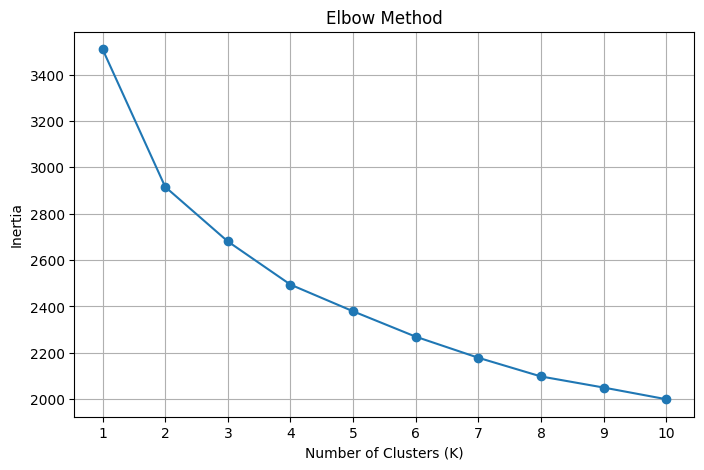

In [15]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate WCSS (Inertia) for different K values
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [17]:
# Create the K-Means model
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model
cluster_labels = kmeans_model.fit_predict(X_cluster_scaled)

print("K-Means model trained successfully!")
print("Cluster labels:", cluster_labels)

K-Means model trained successfully!
Cluster labels: [1 0 2 1 0 2 1 1 1 1 2 1 2 2 0 0 1 1 2 2 1 2 2 2 0 0 0 0 1 0 2 1 2 1 1 1 1
 0 2 2 2 0 2 2 1 2 2 2 1 1 1 2 0 0 0 2 1 0 0 1 2 1 2 0 1 1 2 0 0 2 1 0 0 0
 0 1 1 2 2 2 1 1 1 2 1 2 2 1 0 1 2 0 1 1 2 1 0 2 0 0 2 1 0 1 1 2 2 1 2 2 1
 2 0 0 2 0 2 1 0 1 1 1 1 0 2 0 1 0 2 1 0 1 2 1 2 0 0 1 2 2 1 2 2 2 2 1 2 1
 1 0 2 0 0 0 0 2 1 2 2 1 2 0 2 1 2 0 0 2 0 2 0 1 1 0 2 1 1 2 1 2 2 1 2 0 2
 2 1 2 0 1 2 1 2 2 2 0 0 0 0 1 2 2 1 2 1 2 0 1 1 2 2 2 2 1 2 2 0 2 2 2 1 1
 2 1 2 2 1 1 0 2 1 2 2 2 1 1 0 1 2 2 1 2 0 1 0 1 1 0 2 1 1 2 2 2 2 0 1 1 0
 2 0 1 2 2 2 2 2 0 2 1]


In [18]:
from sklearn.metrics import silhouette_score

# Calculate Silhouette Score
sil_score = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.1275929192959853


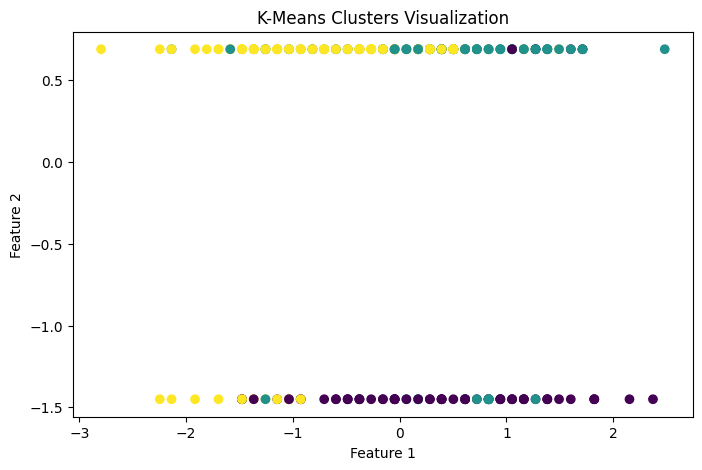

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_cluster_scaled[:, 0],
    X_cluster_scaled[:, 1],
    c=cluster_labels,
    cmap='viridis'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clusters Visualization')
plt.show()